In [2]:
%pip install request
%pip install beautifulsoup4

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement request (from versions: none)

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for request


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import requests
from bs4 import BeautifulSoup
import pandas as pd

In [4]:
headers={"User-Agent": "Mozilla/5.0"}
url="https://www.99acres.com/property-in-lucknow-ffid"

response=requests.get(url, headers=headers)
soup= BeautifulSoup(response.content, "html.parser")


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
df=pd.read_csv(r"C:\Users\Ausaaf Siddiqui\OneDrive\Desktop\STUDY MATERIAL\Data Science Project\lucknow_hosuing_prices - Main File.csv")
df.shape
df.head()
df.info()
df.describe()

<class 'pandas.DataFrame'>
RangeIndex: 474 entries, 0 to 473
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   bhk          474 non-null    int64  
 1   type         474 non-null    str    
 2   area_sq_ft   474 non-null    int64  
 3   location     474 non-null    str    
 4   price_lakh   474 non-null    float64
 5   carpet_area  322 non-null    str    
 6   status       474 non-null    str    
 7   bathrooms    474 non-null    int64  
dtypes: float64(1), int64(3), str(4)
memory usage: 29.8 KB


,bhk,area_sq_ft,price_lakh,bathrooms
count,474.000000,474.000000,474.000000,474.000000
mean,2.120253,1060.632911,38.749325,1.997890
std,0.460135,236.629210,10.013490,0.413815
min,1.000000,350.000000,6.990000,1.000000
25%,2.000000,926.250000,32.000000,2.000000
50%,2.000000,1050.000000,40.750000,2.000000
75%,2.000000,1250.000000,46.000000,2.000000
max,4.000000,1617.000000,50.000000,5.000000


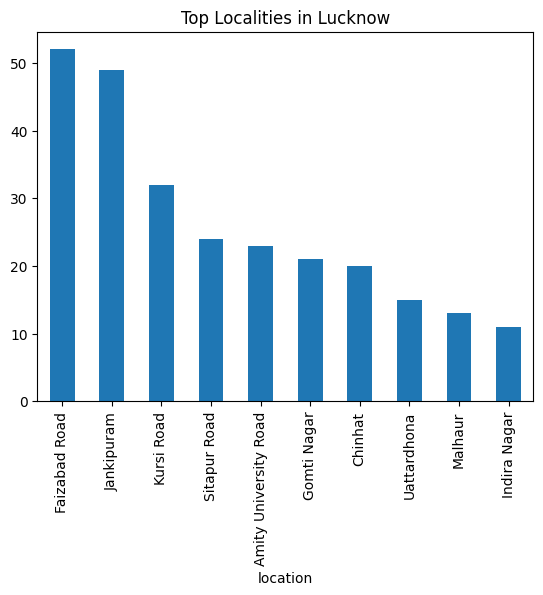

In [7]:
df['location'].value_counts().head(10).plot(kind='bar')
plt.title('Top Localities in Lucknow')
plt.show()

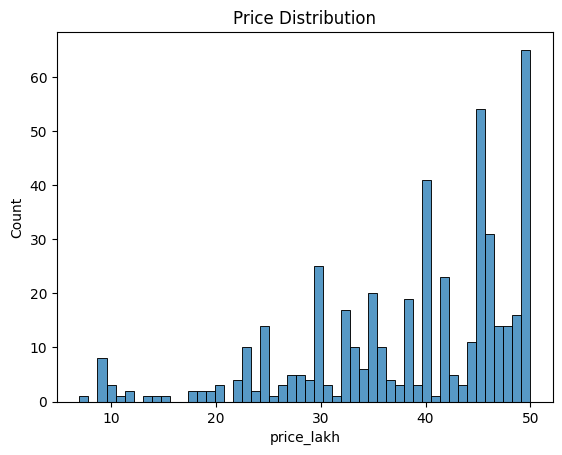

In [8]:
sns.histplot(df['price_lakh'], bins=50)
plt.title('Price Distribution')
plt.show()

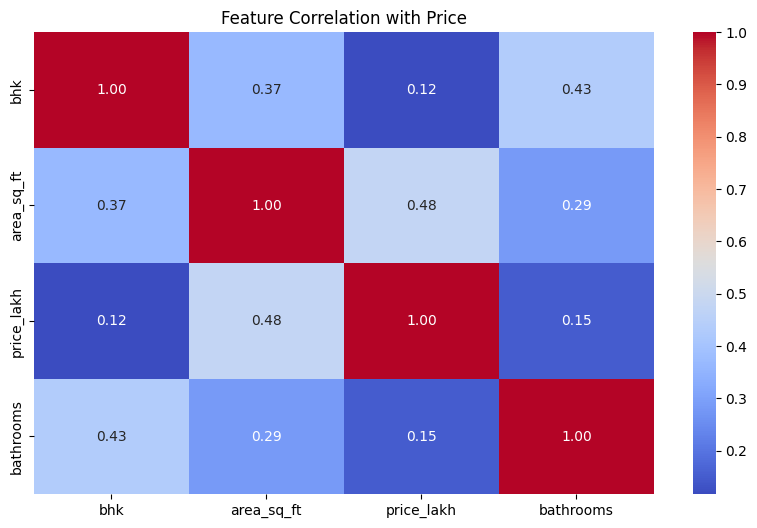

In [33]:
plt.figure(figsize=(10, 6))
sns.heatmap(df[['bhk', 'area_sq_ft', 'price_lakh', 'bathrooms']].corr(),
            annot=True, cmap='coolwarm', fmt='.2f')
plt.title("Feature Correlation with Price")
plt.show()

In [10]:
df.groupby('location')['price_lakh'].mean().sort_values(ascending=False).head(10)

location
2Bhk                                     50.0
Amity University Road University Road    50.0
Sikander Pur                             50.0
Sharda Nagar                             50.0
Vijay Nagar                              50.0
Hitashie Empire                          49.5
Anora Kala                               49.5
Hitashieempire                           49.0
Bbd College                              49.0
Krishna                                  49.0
Name: price_lakh, dtype: float64

In [11]:
df.isnull().sum()

bhk              0
type             0
area_sq_ft       0
location         0
price_lakh       0
carpet_area    152
status           0
bathrooms        0
dtype: int64

In [12]:
df['carpet_area'].fillna('Not Available', inplace=True)

C:\Users\Ausaaf Siddiqui\AppData\Local\Temp\ipykernel_6208\1121744652.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['carpet_area'].fillna('Not Available', inplace=True)


0                720
1      Not Available
2               1000
3                900
4                   
           ...      
469             1100
470             1000
471    Not Available
472    Not Available
473              786
Name: carpet_area, Length: 474, dtype: str

In [30]:
Q1= df['price_lakh'].quantile(0.05)
Q3= df['price_lakh'].quantile(0.95)
df=df[(df['price_lakh']>=Q1) & (df['price_lakh']<=Q3)]

In [14]:
df['location']= df['location'].str.strip().str.title()
df['location']= df['location'].str.replace({
    "Devaroad": "Deva Road",
    "Chinhut": "Chinhat",
    "Amity University Road University Road": "Amity University Road",
    "Bbd Road": "BBD Road",
    "Siknder Pur": "Sikanderpur",
    "Iim Road": "IIM Road",
})

In [15]:
df['Price_per_sqft']= df['price_lakh']/df['area_sq_ft']

premium_areas=['Gomti Nagar', 'Indira Nagar', 'Aliganj', 'Vikas Nagar', 'Mahanagar']
df['is_premium_area']=df['location'].isin(premium_areas).astype(int)

df['carpet_area'] = pd.cut(pd.to_numeric(df['carpet_area'], errors='coerce'),
                          bins=[0, 2, 6, 100],
                          labels=['Low', 'Mid', 'High'])

In [16]:
df=pd.get_dummies(df, columns=['location', 'status','type'])

In [17]:
X=df.drop('price_lakh', axis=1)
Y=df['price_lakh']

In [18]:
%pip install scikit_learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [19]:
from sklearn.model_selection import train_test_split

In [20]:
X_train, X_test, Y_train, Y_test=train_test_split(X, Y, train_size=0.2, random_state=42)

In [21]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [22]:

print(df.dtypes[df.dtypes == 'object'])        
print(df.dtypes[df.dtypes == 'category'])       

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in df.select_dtypes(include=['object', 'category']).columns:
    df[col] = le.fit_transform(df[col].astype(str))
    print(f"Encoded: {col}")


Series([], dtype: object)
carpet_area    category
dtype: object
Encoded: carpet_area


In [32]:
X = df.drop('price_lakh', axis=1)
y = df['price_lakh']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    'Linear Regression': LinearRegression(),
    'Decision Tree': DecisionTreeRegressor(),
    'Random Forest': RandomForestRegressor()
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    mae = mean_absolute_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)
    print(f"{name} → MAE: ₹{mae:.2f} Lakhs | R² Score: {r2:.3f}")

Linear Regression → MAE: ₹1.22 Lakhs | R² Score: 0.903
Decision Tree → MAE: ₹1.08 Lakhs | R² Score: 0.923
Random Forest → MAE: ₹0.80 Lakhs | R² Score: 0.960


In [24]:
from sklearn.ensemble import GradientBoostingRegressor

In [ ]:
base_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=4,
)
base_model.fit(X_train, y_train)

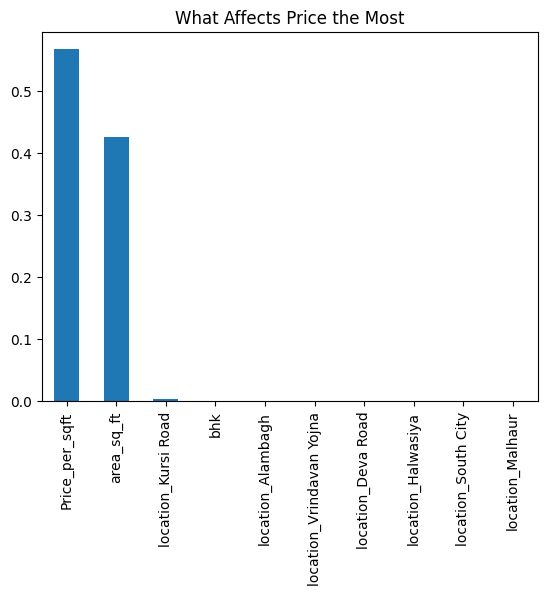

In [36]:
importances = pd.Series(base_model.feature_importances_, index=X.columns)
importances.sort_values(ascending=False).head(10).plot(kind='bar')
plt.title("What Affects Price the Most")
plt.show()

In [ ]:
plt.figure(figsize=(8, 6))
plt.figure(figsize=(8, 6))
y_pred = base_model.predict(X_test)
plt.scatter(y_test, y_pred, alpha=0.5, color='steelblue')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Price (₹ Lakhs)")
plt.ylabel("Predicted Price (₹ Lakhs)")
plt.title("Actual vs Predicted Prices")
plt.show()
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel("Actual Price (₹ Lakhs)")
plt.ylabel("Predicted Price (₹ Lakhs)")
plt.title("Actual vs Predicted Prices")
plt.show()

In [37]:
new_house_array = pd.DataFrame(0, index=[0], columns=X.columns)
new_house_array.loc[0, 'area_sq_ft'] = 1500
new_house_array.loc[0, 'bhk'] = 3
new_house_array.loc[0, 'bathrooms'] = 2
new_house_array.loc[0, 'Price_per_sqft'] = 1500 / 1500
new_house_array.loc[0, 'is_premium_area'] = 1
new_house_array.loc[0, 'location_Gomti Nagar'] = 1
prediction = base_model.predict(new_house_array)
print(f"Predicted Price: ₹{prediction[0]:.2f} Lakhs")

Predicted Price: ₹55.28 Lakhs


In [38]:
%pip install pickle

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement pickle (from versions: none)

[notice] A new release of pip is available: 25.3 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip
ERROR: No matching distribution found for pickle


In [39]:
import json
params = base_model.get_params()
with open('output/model_params.json', 'w') as f:
    json.dump(params, f, indent=4)